In [50]:
import math
import numpy as np
import matplotlib.pyplot as plt
import torch
%matplotlib inline

In [6]:
words = open('/Users/cono/code/learning_ml/src/ml_learning/makemore_conor/names.txt', 'r').read().splitlines()

In [229]:
words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [231]:
print(len(words))

n = 0
for w in words:
    chs = ['.'] + list(w) + ['.']
    n += len(chs) - 1

print(n)
print(nll / n)

32033
228146
tensor(2.4544)


In [216]:
# using torch.tensor, compute bigram
special_char = 1
total_chars = 26 + special_char
bigram = torch.zeros((total_chars,total_chars), dtype=torch.int32)

In [217]:
# We had S/E special tokens, but now just "."
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}

In [218]:
for w in words:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    bigram[ix1, ix2] += 1

In [210]:
for w in words:
    chs = ["."] + list(w) + ["."]
    #print(chs)
    for ch1, ch2 in zip(chs, chs[1:]):
        bigram[stoi[ch1]][stoi[ch2]] += 1

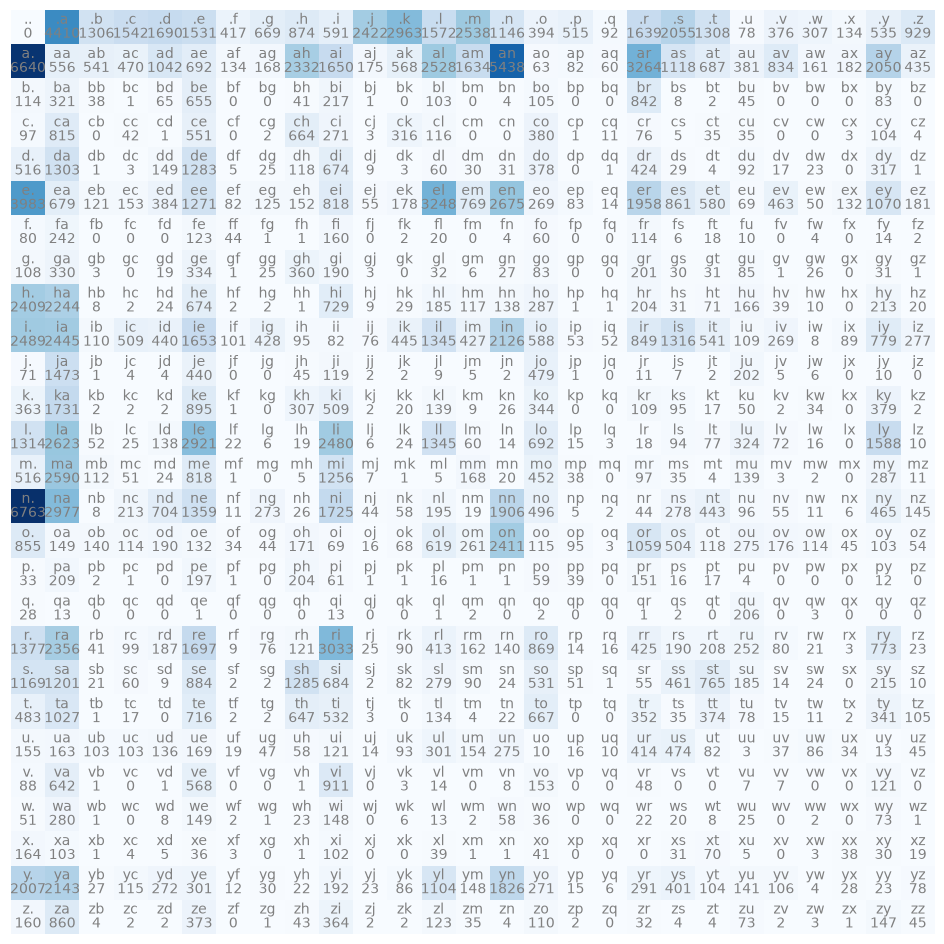

In [219]:
plt.figure(figsize=(12,12))
plt.imshow(bigram, cmap="Blues")
for i in range(total_chars):
    for j in range(total_chars):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha="center", va="bottom", color='gray')
        plt.text(j, i, bigram[i,j].item(), ha="center", va="top", color='gray')
plt.axis('off');

In [110]:
# datatypes - torch tensor 1x1 versus item (int)

In [111]:
# Now we can sample from this matrix. My attempt

In [220]:
import random
import bisect
def sample(row_idx):
    r = random.uniform(0,1)
    idx = math.floor(r * bigram[row_idx,:].sum())
    cs = bigram[row_idx,:].cumsum(axis=0)
    choice = bisect.bisect_left(list(cs), idx)

    return itos[choice]

In [221]:
p = bigram[0].float()
p = p/ p.sum()
p

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

In [222]:
g = torch.Generator().manual_seed(2147483647)
ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
itos[ix]

'c'

In [224]:
# can use a pytorch thing - verify what these do
g = torch.Generator().manual_seed(2147483647)
ix = torch.multinomial(p, num_samples=20, replacement=True, generator=g)
#[itos[i.item()] for i in ix]

In [225]:
g = torch.Generator().manual_seed(2147483647)
ix = 0
word = ""
it = 0
while True:
    p = bigram[ix].float()
    p = p / p.sum()
    ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
    if ix == 0:
        break
    word += itos[ix]
    it += 1

print(word)

cexze


In [240]:
# vectorise - protect from 0 sum
g = torch.Generator().manual_seed(2147483647)
ix = 0
word = ""
it = 0
# Model smoothing - see below
P = (bigram + 1).float()
P /= P.sum(axis=1, keepdim=True)
while True:
    ix = torch.multinomial(P[ix], num_samples=1, replacement=True, generator=g).item()
    if ix == 0:
        break
    word += itos[ix]
    it += 1

print(word)

cexze


In [190]:
# difference in defining p when we don't use keepdim? Broadcasting semantics... says it will [27] -> [1,27]
# its a row vector now - divides against rows, not columns

In [191]:
# Moving on to NN training

In [233]:
# GOAL: maximize likelihood of the data w.r.t. model parameters (statistical modeling) i.e. the bigram counts
# equivalent to maximizing the log likelihood (because log is monotonic)
# equivalent to minimizing the negative log likelihood
# equivalent to minimizing the average negative log likelihood

# log(a*b*c) = log(a) + log(b) + log(c)

In [239]:
log_likelihood = 0.0
n = 0

for w in words:
#for w in ["andrejq"]:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    prob = P[ix1, ix2]
    logprob = torch.log(prob)
    log_likelihood += logprob
    n += 1
    #print(f'{ch1}{ch2}: {prob:.4f} {logprob:.4f}')

print(f'{log_likelihood=}')
nll = -log_likelihood
print(f'{nll=}')
print(f'{nll/n}')

log_likelihood=tensor(-559951.5625)
nll=tensor(559951.5625)
2.4543561935424805


In [238]:
# Note that if we get "c1c2" which doesn't exist in the dataset, we'll get p = 0, and hence log likelihood = -inf
# Model smoothing - add fake counts, add 1 to everything. Adding more smooths more and pushes it to equal-weighted

In [242]:
# Now lets train to get the best NLL
# NN is going to go character -> probability of what comes next
# create training set

In [326]:
# create training set
xs, ys = [], []

for w in words[:1]:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    xs.append(ix1)
    ys.append(ix2)

xs = torch.tensor(xs)
ys = torch.tensor(ys)

In [327]:
# note tensor and Tensor are different (?) tensor generally better

In [328]:
xs.dtype

torch.int64

In [329]:
# What should input be? Integers doesn't make sense (why would you multiply by an index??)
# We'll use one_hot encoding for now
# torch.nn.functional.one_hot

In [330]:
import torch.nn.functional as F
# dtype preserved from xs unless otherwise (?)
xenc = F.one_hot(xs, num_classes=27).float()
xenc

tensor([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.]])

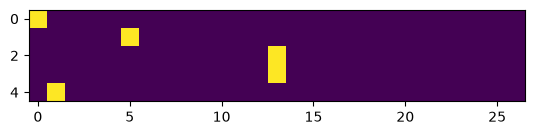

In [331]:
plt.imshow(xenc)

In [332]:
xenc.dtype

torch.float32

In [333]:
xenc.shape

torch.Size([5, 27])

In [334]:
# randn - tensor of shape with std normal
# for each of 27 neurons, what is firing rate on the qth input
# (xenc @ W)[3,13] - 13th neuron, 3rd example
W = torch.randn((27, 27))
xenc @ W

tensor([[-1.1454, -0.6313, -2.3240, -0.5317,  0.3859, -0.3849, -0.6212,  0.0379,
         -0.0378, -1.2044, -0.2138,  2.0861, -0.3146,  0.9711, -0.1928,  1.0432,
          0.1730,  2.6446,  0.4517, -0.0346, -1.5501, -1.2631,  0.3749, -0.0796,
          1.1193,  1.3738, -0.3020],
        [ 0.9210, -0.1060, -0.2228, -0.2672, -1.3430, -0.7362,  1.3200, -0.2383,
          0.8617,  0.5223,  0.1854, -0.6461,  1.1806,  0.0033,  0.2076,  0.8033,
         -0.5619, -1.2003,  0.3773, -0.8818, -0.9994, -0.1050,  0.7680,  0.4387,
         -1.1372, -0.5724, -0.6411],
        [ 0.3860,  0.7505, -0.2326,  1.3458,  0.7756,  0.1759, -0.3124,  0.4692,
         -0.9830,  0.1819, -0.8775,  1.5434, -1.4420,  0.6084,  0.6395, -0.0047,
          1.3110, -1.7928, -0.5787,  0.7339,  1.0149,  1.9457, -0.9744, -0.6068,
         -0.7925, -0.3511,  0.4384],
        [ 0.3860,  0.7505, -0.2326,  1.3458,  0.7756,  0.1759, -0.3124,  0.4692,
         -0.9830,  0.1819, -0.8775,  1.5434, -1.4420,  0.6084,  0.6395, -0.0047

In [335]:
(xenc @ W)[3,13]

tensor(0.6084)

In [336]:
# Now see that one-hot encoding is just taking the a particular element of the matrix
xenc[3]

tensor([0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
        0., 0., 0., 0., 0., 0., 0., 0., 0.])

In [337]:
(xenc[3] * W[:,13]).sum()

tensor(0.6084)

In [338]:
xenc[3] * W[:,13]

tensor([0.0000, 0.0000, -0.0000, 0.0000, 0.0000, 0.0000, 0.0000, -0.0000, -0.0000,
        0.0000, 0.0000, -0.0000, -0.0000, 0.6084, -0.0000, -0.0000, -0.0000, 0.0000,
        -0.0000, -0.0000, 0.0000, 0.0000, 0.0000, -0.0000, 0.0000, 0.0000, 0.0000])

In [339]:
# trying to produce probability definition - softmax
# interpret outputs as log counts - exponentiate them, then do probability normalisation - same things

In [340]:
logits = xenc @ W # log-counts, recall "logit"
counts = logits.exp() # equivalent to bigram
probs = counts / counts.sum(1, keepdims=True)
probs

tensor([[0.0063, 0.0105, 0.0019, 0.0116, 0.0289, 0.0134, 0.0106, 0.0204, 0.0189,
         0.0059, 0.0159, 0.1584, 0.0144, 0.0519, 0.0162, 0.0558, 0.0234, 0.2768,
         0.0309, 0.0190, 0.0042, 0.0056, 0.0286, 0.0182, 0.0602, 0.0777, 0.0145],
        [0.0764, 0.0274, 0.0243, 0.0233, 0.0079, 0.0146, 0.1138, 0.0240, 0.0720,
         0.0513, 0.0366, 0.0159, 0.0990, 0.0305, 0.0374, 0.0679, 0.0173, 0.0092,
         0.0444, 0.0126, 0.0112, 0.0274, 0.0655, 0.0472, 0.0098, 0.0172, 0.0160],
        [0.0324, 0.0466, 0.0174, 0.0845, 0.0478, 0.0262, 0.0161, 0.0352, 0.0082,
         0.0264, 0.0091, 0.1030, 0.0052, 0.0404, 0.0417, 0.0219, 0.0816, 0.0037,
         0.0123, 0.0458, 0.0607, 0.1540, 0.0083, 0.0120, 0.0100, 0.0155, 0.0341],
        [0.0324, 0.0466, 0.0174, 0.0845, 0.0478, 0.0262, 0.0161, 0.0352, 0.0082,
         0.0264, 0.0091, 0.1030, 0.0052, 0.0404, 0.0417, 0.0219, 0.0816, 0.0037,
         0.0123, 0.0458, 0.0607, 0.1540, 0.0083, 0.0120, 0.0100, 0.0155, 0.0341],
        [0.0675, 0.0690,

In [341]:
# Summary

In [342]:
# randomly initialize 27 neurons' weights. each neuron receives 27 inputs
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g)

In [343]:
xenc = F.one_hot(xs, num_classes=27).float() # input to the network: one-hot encoding
logits = xenc @ W # predict log-counts
counts = logits.exp() # counts, equivalent to N
probs = counts / counts.sum(1, keepdims=True) # probabilities for next character
# btw: the last 2 lines here are together called a 'softmax' - numerically stable. Gumbel

In [344]:
probs.shape

torch.Size([5, 27])

In [345]:
nlls = torch.zeros(5)
for i in range(5):
  # i-th bigram:
  x = xs[i].item() # input character index
  y = ys[i].item() # label character index
  print('--------')
  print(f'bigram example {i+1}: {itos[x]}{itos[y]} (indexes {x},{y})')
  print('input to the neural net:', x)
  print('output probabilities from the neural net:', probs[i])
  print('label (actual next character):', y)
  p = probs[i, y]
  print('probability assigned by the net to the the correct character:', p.item())
  logp = torch.log(p)
  print('log likelihood:', logp.item())
  nll = -logp
  print('negative log likelihood:', nll.item())
  nlls[i] = nll

print('=========')
print('average negative log likelihood, i.e. loss =', nlls.mean().item())

--------
bigram example 1: .e (indexes 0,5)
input to the neural net: 0
output probabilities from the neural net: tensor([0.0607, 0.0100, 0.0123, 0.0042, 0.0168, 0.0123, 0.0027, 0.0232, 0.0137,
        0.0313, 0.0079, 0.0278, 0.0091, 0.0082, 0.0500, 0.2378, 0.0603, 0.0025,
        0.0249, 0.0055, 0.0339, 0.0109, 0.0029, 0.0198, 0.0118, 0.1537, 0.1459])
label (actual next character): 5
probability assigned by the net to the the correct character: 0.012286250479519367
log likelihood: -4.3992743492126465
negative log likelihood: 4.3992743492126465
--------
bigram example 2: em (indexes 5,13)
input to the neural net: 5
output probabilities from the neural net: tensor([0.0290, 0.0796, 0.0248, 0.0521, 0.1989, 0.0289, 0.0094, 0.0335, 0.0097,
        0.0301, 0.0702, 0.0228, 0.0115, 0.0181, 0.0108, 0.0315, 0.0291, 0.0045,
        0.0916, 0.0215, 0.0486, 0.0300, 0.0501, 0.0027, 0.0118, 0.0022, 0.0472])
label (actual next character): 13
probability assigned by the net to the the correct character:

In [346]:
# --------- !!! OPTIMIZATION STEP !!! --------------

In [347]:
# randomly initialize 27 neurons' weights. each neuron receives 27 inputs
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g, requires_grad=True)

In [349]:
# forward pass
xenc = F.one_hot(xs, num_classes=27).float() # input to the network: one-hot encoding
logits = xenc @ W # predict log-counts
counts = logits.exp() # counts, equivalent to N
probs = counts / counts.sum(1, keepdims=True) # probabilities for next character
# See you get this
loss = -probs[torch.arange(5), ys].log().mean()

In [350]:
print(loss.item())

3.7693049907684326


In [352]:
# backward pass
W.grad = None # set to zero the gradient (why None and not zero? Because W is a tensor, seems to be standard)
loss.backward()

In [310]:
W.data += -0.1 * W.grad

In [311]:
# --------- !!! OPTIMIZATION !!! but this time actually --------------

In [360]:
# create the dataset
xs, ys = [], []
for w in words:
  chs = ['.'] + list(w) + ['.']
  for ch1, ch2 in zip(chs, chs[1:]):
    ix1 = stoi[ch1]
    ix2 = stoi[ch2]
    xs.append(ix1)
    ys.append(ix2)
xs = torch.tensor(xs)
ys = torch.tensor(ys)
num = xs.nelement()
print('number of examples: ', num)

# initialize the 'network' - note that weights need grad
g = torch.Generator().manual_seed(2147483647)
# W all 0 is like max smoothing from above
W = torch.randn((27, 27), generator=g, requires_grad=True)

number of examples:  228146


In [361]:
# gradient descent
for k in range(1000):
  
  # forward pass
  xenc = F.one_hot(xs, num_classes=27).float() # input to the network: one-hot encoding
  logits = xenc @ W # predict log-counts - just takes rows of W. See the connection to the count procedure!
  counts = logits.exp() # counts, equivalent to N
  probs = counts / counts.sum(1, keepdims=True) # probabilities for next character
  # Note we regularise below
  loss = -probs[torch.arange(num), ys].log().mean() + 0.01*(W**2).mean()
  print(loss.item())
  
  # backward pass
  W.grad = None # set to zero the gradient
  loss.backward()
  
  # update
  W.data += -5 * W.grad

3.7686190605163574
3.723348617553711
3.6806228160858154
3.6401913166046143
3.601855754852295
3.565463066101074
3.5308804512023926
3.498000383377075
3.4667248725891113
3.4369659423828125
3.4086480140686035
3.381696939468384
3.3560471534729004
3.3316330909729004
3.3083906173706055
3.2862536907196045
3.2651638984680176
3.2450599670410156
3.225883722305298
3.20758056640625
3.1900951862335205
3.173377513885498
3.157377004623413
3.1420505046844482
3.127354621887207
3.113250255584717
3.0997016429901123
3.086674451828003
3.0741398334503174
3.0620689392089844
3.0504350662231445
3.0392165184020996
3.0283899307250977
3.0179364681243896
3.0078372955322266
2.9980742931365967
2.988632917404175
2.9794974327087402
2.970653772354126
2.962089776992798
2.9537932872772217
2.9457521438598633
2.937955617904663
2.930393695831299
2.92305588722229
2.9159343242645264
2.9090194702148438
2.9023027420043945
2.8957769870758057
2.8894336223602295
2.8832662105560303
2.877267360687256
2.8714306354522705
2.865750312805

In [356]:
# Not much different than before, will be better if we complexify neural net

In [316]:
# finally, sample from the 'neural net' model
g = torch.Generator().manual_seed(2147483647)

for i in range(5):
  
  out = []
  ix = 0
  while True:
    
    # ----------
    # BEFORE:
    #p = P[ix]
    # ----------
    # NOW:
    xenc = F.one_hot(torch.tensor([ix]), num_classes=27).float()
    logits = xenc @ W # predict log-counts
    counts = logits.exp() # counts, equivalent to N
    p = counts / counts.sum(1, keepdims=True) # probabilities for next character
    # ----------
    
    ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
    out.append(itos[ix])
    if ix == 0:
      break
  print(''.join(out))

cexze.
momasurailezityha.
konimittain.
llayn.
ka.
